<a href="https://colab.research.google.com/github/tvml/ml2627/blob/master/codici/linregr_gradient.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Regressione lineare con discesa del gradiente

Nelle note i parametri di un modello lineare con loss quadratica sono ottenuti **in forma chiusa**, con le equazioni normali $\overline{\mathbf{w}}^*=(\overline{\mathbf{X}}^T\overline{\mathbf{X}})^{-1}\overline{\mathbf{X}}^T\mathbf{t}$. Questo è possibile perché il rischio empirico è una funzione quadratica e convessa dei parametri. Quando il numero di feature è grande, quando la loss non è quadratica o quando il modello non è lineare nei parametri (come nelle reti neurali), una soluzione in forma chiusa non è disponibile o non è conveniente, e si ricorre a **metodi iterativi** di ottimizzazione, discussi nelle note.

Questo notebook applica alla regressione lineare tre di questi metodi, confrontandoli con la soluzione esatta:

- la **discesa del gradiente** (batch), che a ogni passo usa il gradiente calcolato su tutto il training set;
- la **discesa del gradiente stocastica** (SGD), che aggiorna i parametri dopo ogni singolo elemento;
- la discesa del gradiente con **momento**, che accumula una "velocità" lungo le direzioni di discesa persistenti.

L'attenzione è sul ruolo del **learning rate** $\eta$ (nel titolo originale indicato come $\alpha$): troppo piccolo rende la convergenza lenta, troppo grande la rende instabile.

## Preparazione

Importiamo `pandas` per leggere il dataset, `numpy` per i calcoli, `seaborn` per i grafici e `matplotlib` per le parti che seaborn non copre (le mappe di colore con `imshow` e il modulo per i grafici tridimensionali).

In [1]:
%matplotlib inline

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.colors as mcolors
from matplotlib import cm
from mpl_toolkits.mplot3d import Axes3D

In [2]:
import warnings
warnings.filterwarnings('ignore')

Definizioni relative alla visualizzazione

In [3]:
sns.set_theme(style='whitegrid', palette='deep')

plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.serif'] = 'Ubuntu'
plt.rcParams['font.monospace'] = 'Ubuntu Mono'
plt.rcParams['font.size'] = 10
plt.rcParams['axes.labelsize'] = 10
plt.rcParams['axes.labelweight'] = 'bold'
plt.rcParams['axes.titlesize'] = 10
plt.rcParams['xtick.labelsize'] = 8
plt.rcParams['ytick.labelsize'] = 8
plt.rcParams['legend.fontsize'] = 10
plt.rcParams['figure.titlesize'] = 12
plt.rcParams['image.cmap'] = 'jet'
plt.rcParams['image.interpolation'] = 'none'
plt.rcParams['figure.figsize'] = (16, 8)
plt.rcParams['lines.linewidth'] = 2
plt.rcParams['lines.markersize'] = 8

colors = ['xkcd:pale orange', 'xkcd:sea blue', 'xkcd:pale red', 'xkcd:sage green', 'xkcd:terra cotta', 'xkcd:dull purple', 'xkcd:teal', 'xkcd:goldenrod', 'xkcd:cadet blue', 
          'xkcd:scarlet']
cmap_big = plt.get_cmap('Spectral', 512)
cmap = mcolors.ListedColormap(cmap_big(np.linspace(0.7, 0.95, 256)))

bbox_props = dict(boxstyle="round,pad=0.3", fc=colors[0], alpha=.5)

La funzione `get_file` permette di usare il notebook sia su Colab (scaricando il file dal sito del corso) sia in locale (leggendolo dalla cartella `../dataset/`).

In [10]:
import urllib.request

filepath = "../dataset/"
url = "https://tvml.github.io/ml2627/dataset/"

def get_file(filename, local=True):
    IS_COLAB = ('google.colab' in str(get_ipython()))
    if IS_COLAB or not local:
        urllib.request.urlretrieve(url+filename, filename)
        return filename
    else:
        return filepath+filename

## Normalizzazione delle feature

La funzione `normalizza` porta ogni feature a media nulla e deviazione standard unitaria (*standardizzazione*). Per la soluzione in forma chiusa questo non è necessario, ma per i metodi a gradiente è molto importante: la forma della superficie dell'errore dipende dalla scala delle feature, e feature con scale molto diverse producono "valli" allungate e strette, in cui la discesa del gradiente procede a zig-zag e converge lentamente (si vedano le note). Dopo la standardizzazione, la superficie è molto più regolare e un unico learning rate funziona bene in tutte le direzioni.

In [5]:
def normalizza(X):
    mu = np.mean(X, axis=0)
    sigma = np.std(X, axis=0, ddof=1)
    return (X-mu)/sigma

## Il dataset

Il dataset `mammals.csv` contiene, per diverse specie di mammiferi, il peso corporeo (`body`) e il peso del cervello (`brain`). Vogliamo predire il secondo a partire dal primo con un modello lineare $h(x)=w_0+w_1x$.

In [9]:
# legge i dati in dataframe pandas
data = pd.read_csv(get_file("mammals.csv", local=False), delimiter=',')

# calcola dimensione dei dati
n = len(data)

Il grafico mostra il dataset. Si noti che le due variabili hanno una distribuzione molto asimmetrica: pochi animali molto grandi hanno valori molto più elevati di tutti gli altri. Questi punti hanno un peso enorme sulla soluzione dei minimi quadrati, che, come discusso nelle note, è sensibile ai valori estremi (la loss quadratica penalizza fortemente i residui grandi). Una pratica comune con dati di questo tipo è lavorare sui logaritmi delle variabili; qui, per semplicità, usiamo i dati originali.

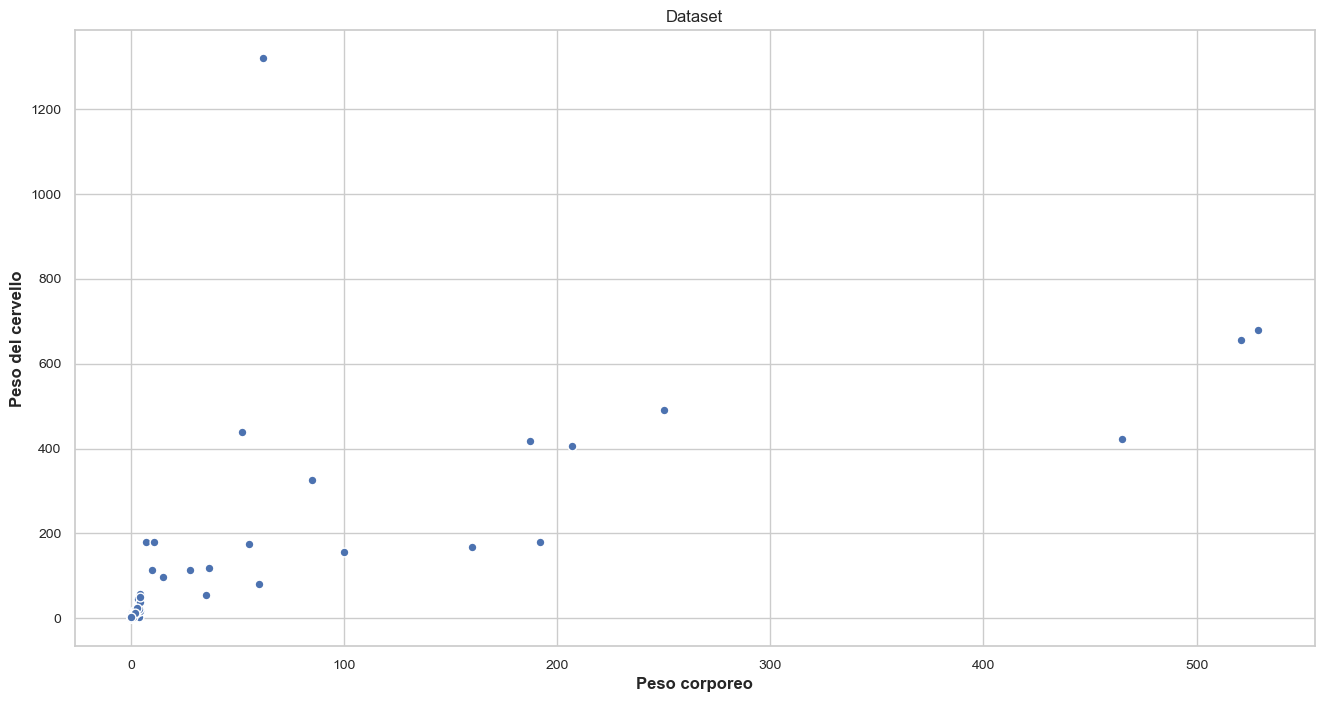

In [12]:
fig = plt.figure(figsize=(16,8))
ax = fig.gca()
sns.scatterplot(x=np.ravel(data.body), y=np.ravel(data.brain), s=40, marker='o', linewidths=1, ax=ax)
plt.xlabel(u'Peso corporeo', fontsize=12)
plt.ylabel('Peso del cervello', fontsize=12)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)
plt.title('Dataset', fontsize=12)
plt.show()

## Preparazione dei dati

Estraiamo la feature e il target, normalizziamo la feature e aggiungiamo una colonna di uni: otteniamo la **matrice di design aumentata** $\overline{\mathbf{X}}$ delle note, in cui il bias $w_0$ è trattato come il coefficiente di una feature costante pari a $1$.

In [13]:
# Estrae dal dataframe gli array X delle features e y dei valori
X, t = np.array(data[['body']]), np.array(data['brain']).reshape((-1,1))

X=normalizza(X)
X = np.column_stack((np.ones(n), X))

## La superficie dell'errore

Calcoliamo il rischio empirico
$$E(\mathbf{w})=\frac1{2n}\sum_{i=1}^n\bigl(\overline{\mathbf{x}}_i^T\mathbf{w}-t_i\bigr)^2=\frac{1}{2n}\|\overline{\mathbf{X}}\mathbf{w}-\mathbf{t}\|^2$$
su una griglia di valori dei due coefficienti $(w_0,w_1)$. Il fattore $1/2$ semplifica l'espressione del gradiente e non cambia la posizione del minimo.

In [14]:
# insieme dei valori considerati per i coefficienti
w0_list = np.linspace(80, 180, 100)
w1_list = np.linspace(80, 180, 100)

# crea una griglia di coppie di valori 
w0, w1 = np.meshgrid(w0_list, w1_list)

# definisce la funzione da calcolare in ogni punto della griglia
def error(v1, v2):
    theta = np.array((v1, v2)).reshape(-1, 1)
    e=(np.dot(X,theta)-t)
    return np.dot(e.T,e)[0,0]/(2*n)

v_error=np.vectorize(error)
e=v_error(w0,w1).T

La superficie è un **paraboloide**: il rischio empirico è una funzione quadratica convessa dei parametri, con un unico minimo globale, che è quello dato dalle equazioni normali. Su una superficie di questo tipo la discesa del gradiente, con un learning rate opportuno, converge sempre al minimo.

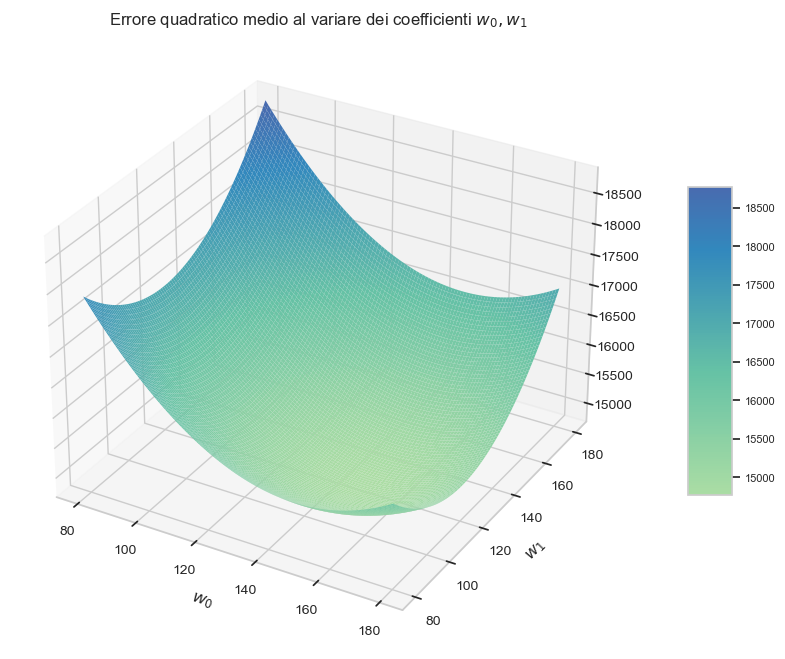

In [15]:
fig = plt.figure(figsize=(16,8))
ax = fig.add_subplot(projection='3d')
surf=ax.plot_surface(w0, w1, e, rstride=1, cstride=1, cmap=cmap , linewidth=0, antialiased=True)
ax.tick_params(axis='x', labelsize=10)
ax.tick_params(axis='y', labelsize=10)
ax.tick_params(axis='z', labelsize=10)
plt.xlabel(r"$w_0$", fontsize=12)
plt.ylabel(r"$w_1$", fontsize=12)
plt.title(r"Errore quadratico medio al variare dei coefficienti $w_0,w_1$", fontsize=12)
fig.colorbar(surf, shrink=0.5, aspect=7)
plt.show()

La stessa funzione rappresentata con una mappa di colori: le curve di livello sono ellissi centrate nel minimo. Grazie alla standardizzazione della feature le ellissi sono quasi circolari; senza di essa sarebbero molto allungate.

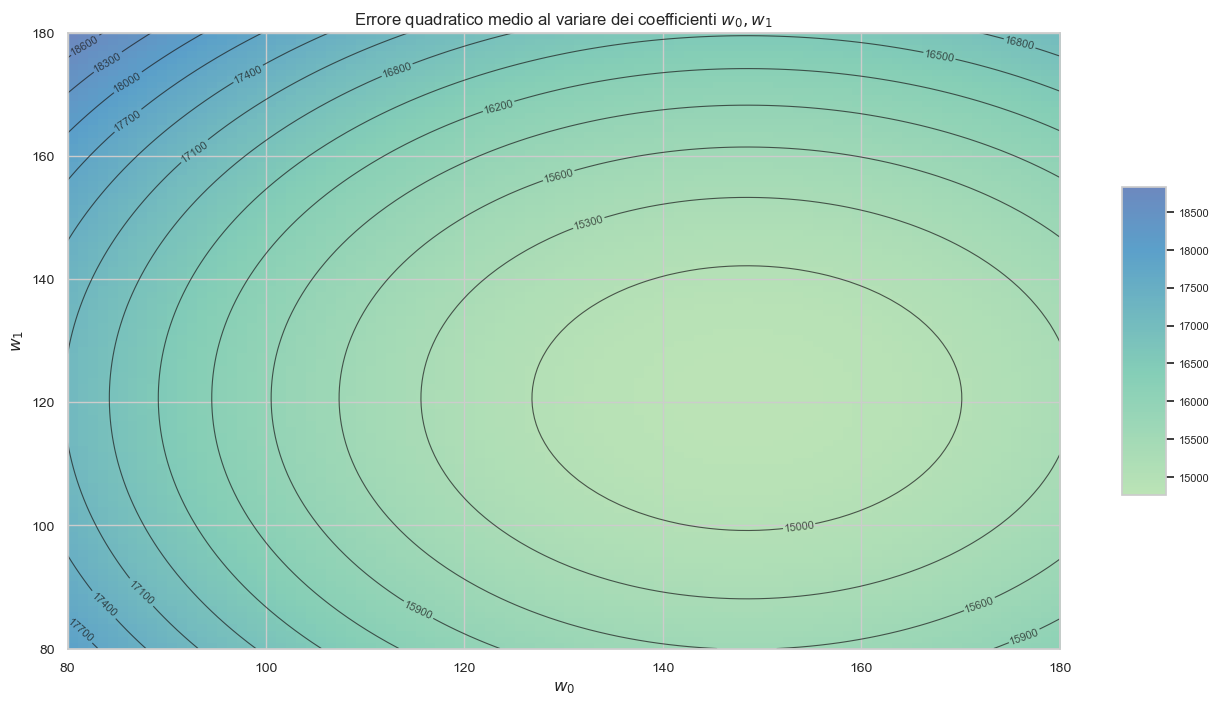

In [17]:
fig = plt.figure(figsize=(16,8))
fig.patch.set_facecolor('white')
ax = fig.gca()
im = plt.imshow(e, origin='lower', cmap=cmap, extent=(w0_list.min(),w0_list.max(),
                w1_list.min(), w1_list.max()), aspect='auto',alpha=.8)
# curve di livello dell'errore, sovrapposte alla mappa di colore
# (e ha una riga per ogni valore di w1 e una colonna per ogni valore di w0, come in imshow)
cs = ax.contour(w0_list, w1_list, e, levels=15, colors='k', linewidths=0.8, alpha=.7)
ax.clabel(cs, inline=True, fontsize=8, fmt='%.0f')
ax.tick_params(axis='x', labelsize=10)
ax.tick_params(axis='y', labelsize=10)
plt.xlabel(r"$w_0$", fontsize=12)
plt.ylabel(r"$w_1$", fontsize=12)
plt.title(r"Errore quadratico medio al variare dei coefficienti $w_0,w_1$", fontsize=12)
fig.colorbar(im, shrink=0.5, aspect=7)
plt.show()

## La soluzione esatta come riferimento

Calcoliamo la soluzione esatta con le equazioni normali e il corrispondente valore minimo del costo, `c_opt`. Fissiamo poi una soglia pari al costo ottimo aumentato del $5\%$: diremo che un metodo iterativo "è arrivato a convergenza" quando il suo costo scende stabilmente sotto questa soglia.

In [18]:
theta = np.dot(np.dot(np.linalg.inv(np.dot(X.T, X)), X.T), t)
e=np.dot(X,theta)-t
c_opt=np.dot(e.T,e)[0,0]/(2*n)
threshold = c_opt+0.05*c_opt

## Discesa del gradiente

Il gradiente del rischio empirico è
$$\nabla E(\mathbf{w})=\frac1n\overline{\mathbf{X}}^T\bigl(\overline{\mathbf{X}}\mathbf{w}-\mathbf{t}\bigr),$$
e la discesa del gradiente aggiorna i parametri muovendosi nella direzione opposta:
$$\mathbf{w}^{(k+1)}=\mathbf{w}^{(k)}-\eta\,\nabla E(\mathbf{w}^{(k)}).$$
La funzione `gradiente` esegue un numero fissato di iterazioni, memorizzando il costo a ogni passo.

In [19]:
# Funzione che applica la ricerca per gradiente memorizzando la sequenza dei costi
def gradiente( X, t, w_init, eta, iterations, n):
    w = np.copy(w_init)
    costs = []
    for i in range(iterations):
        e=np.dot(X,w)-t
        c=np.dot(e.T,e)[0,0]/(2*n)
        dw=np.dot(X.T, e)/n
        w = w-eta*dw
        costs.append(c)
    return costs, w

Partiamo da $\mathbf{w}=\mathbf{0}$ ed eseguiamo $150$ iterazioni per sei diversi valori del learning rate.

In [20]:
# Inizializza il vettore dei coefficienti
w_init = np.array([0, 0]).reshape(-1,1)
iterations = 150
etas = [0.01, 0.03, 0.1, 0.3, 0.5, 1]

number_of_iterations = range(1, iterations + 1)

Per ogni valore di $\eta$ il grafico mostra il costo in funzione del numero di iterazioni; il riquadro indica dopo quante iterazioni il costo scende sotto la soglia, e il titolo riporta il costo finale e i coefficienti trovati.

Con $\eta$ piccolo il costo scende lentamente, e dopo $150$ iterazioni può essere ancora lontano dal minimo; al crescere di $\eta$ la convergenza è sempre più rapida. Per un problema quadratico la discesa del gradiente converge se $\eta<2/L$, dove $L$ è il più grande autovalore della matrice hessiana $\frac1n\overline{\mathbf{X}}^T\overline{\mathbf{X}}$: con la feature standardizzata gli autovalori sono circa $1$, e anche $\eta=1$ converge. Con valori di $\eta$ maggiori di circa $2$, invece, il costo crescerebbe a ogni passo e l'algoritmo divergerebbe: è utile provarlo aggiungendo, ad esempio, $\eta=2.5$ alla lista.

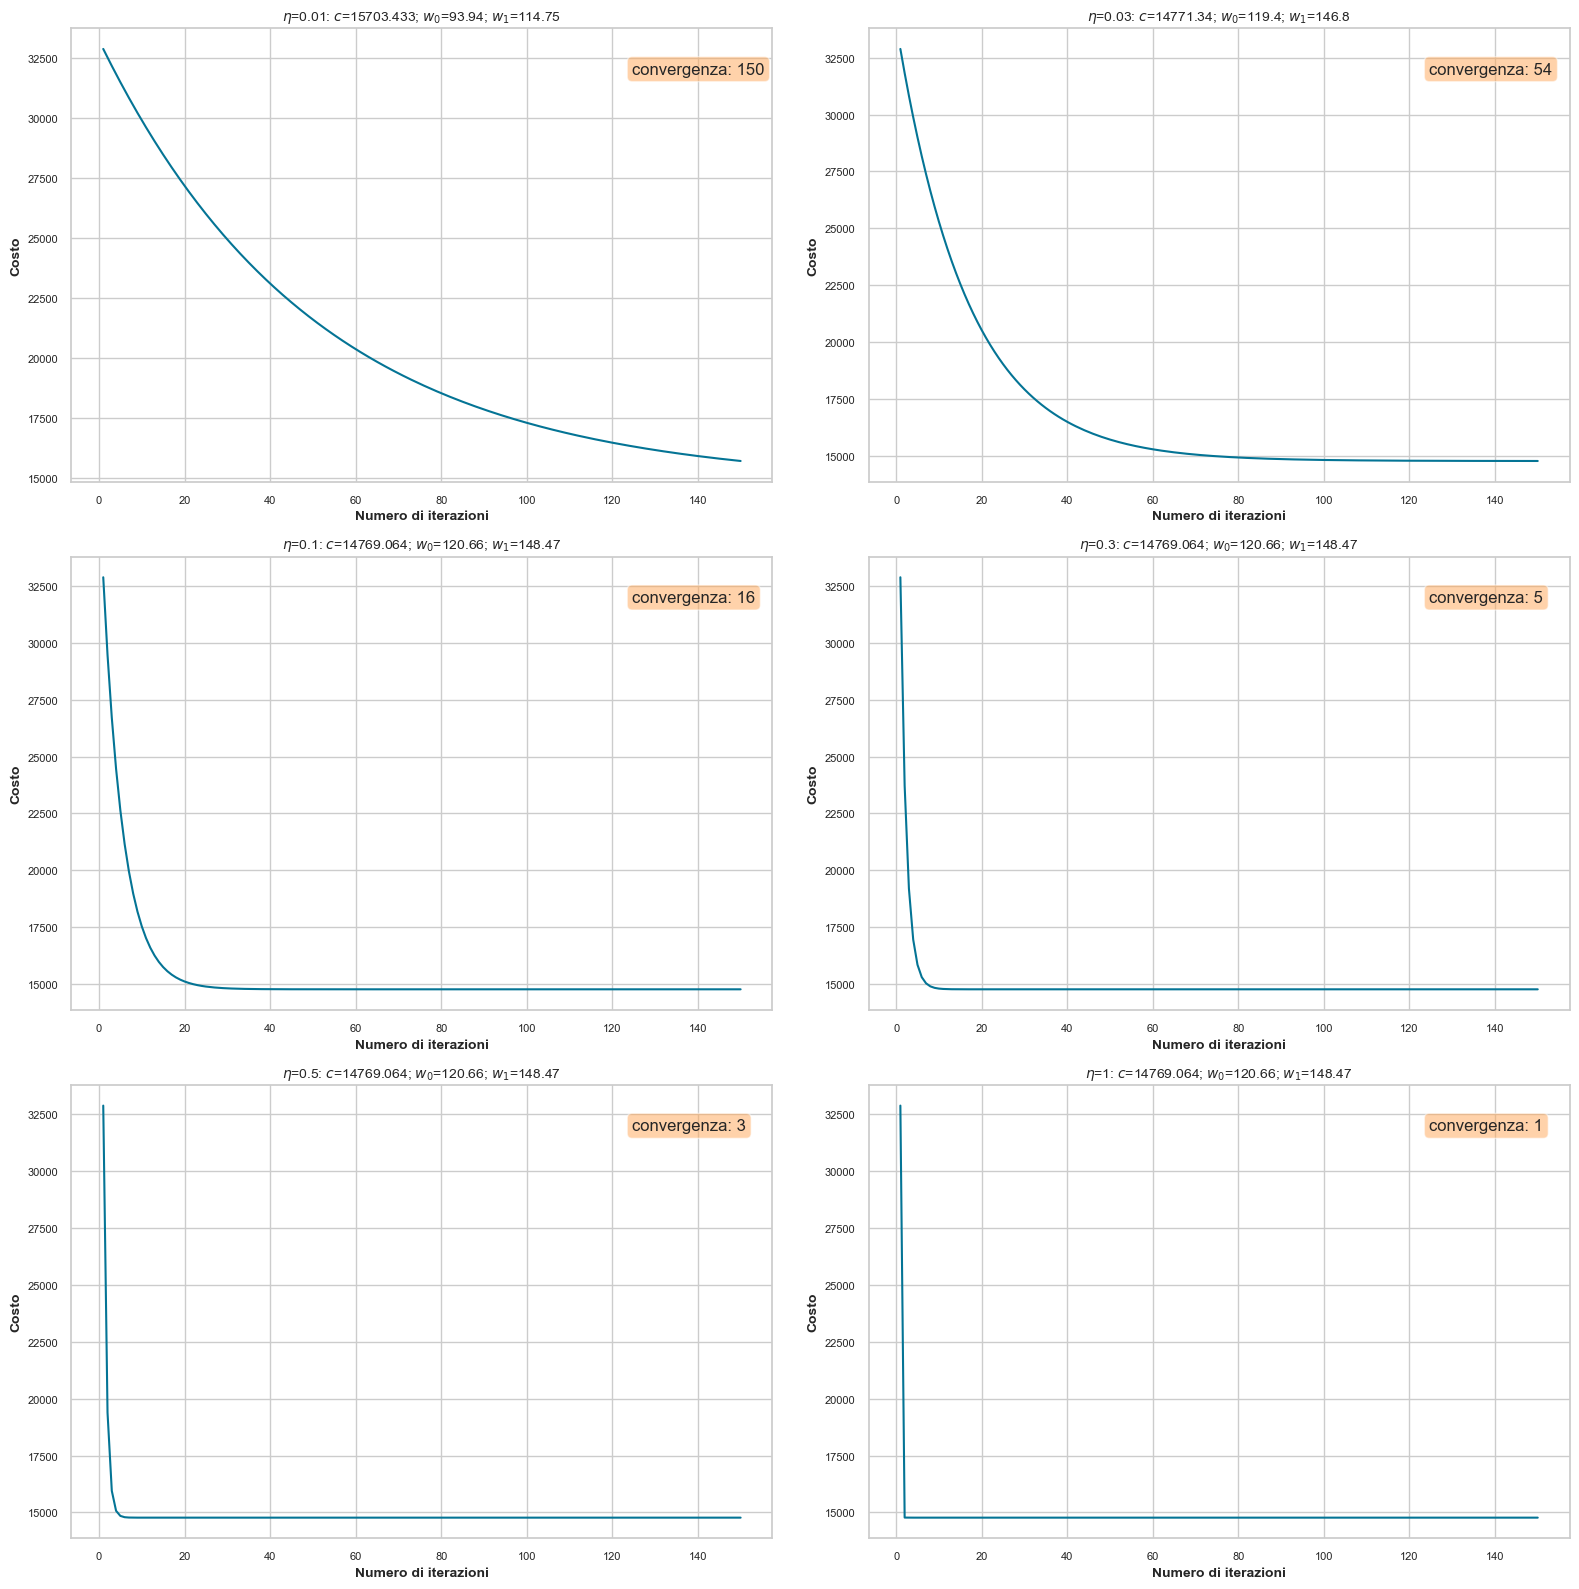

In [21]:
fig = plt.figure(figsize=(16,16))
for c,eta in enumerate(etas):
    costs, w = gradiente(X, t, w_init, eta, iterations, n)
    max_index = np.max(np.where(costs > threshold)[0])+1
    ax = fig.add_subplot(3, 2, c+1)
    ax = fig.gca()
    sns.lineplot(x=np.ravel(number_of_iterations), y=np.ravel(costs), color=colors[1], alpha=1, linewidth=1.5, ax=ax)
    plt.xticks(fontsize=8)
    plt.yticks(fontsize=8)
    plt.xlabel(r'Numero di iterazioni', fontsize=10)
    plt.ylabel(r'Costo', fontsize=10)
    plt.text(0.8, 0.9, 'convergenza: {0:d}'.format(max_index), fontsize=12, 
         transform=ax.transAxes, bbox=bbox_props)
    plt.title(r'$\eta$='+str(eta)+r': $c$='+str(round(costs[-1],3))+r'; $w_0$='+str(round(w[0][0],2))+'; $w_1$='+str(round(w[1][0],2))+'', fontsize=10)
plt.tight_layout()
plt.show()

Lo stesso confronto in un unico grafico.

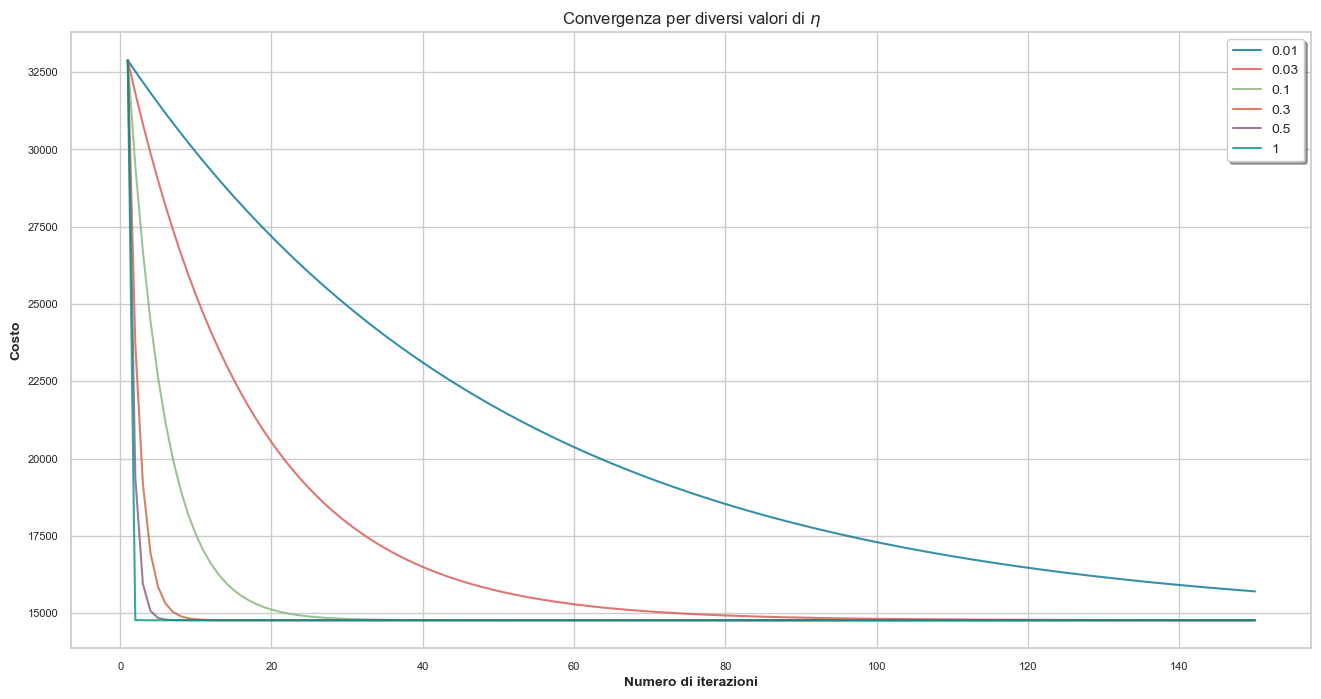

In [22]:
fig = plt.figure(figsize=(16,8))
ax = fig.gca()
for c,eta in enumerate(etas):
    costs, w = gradiente(X, t, w_init, eta, iterations, n)
    sns.lineplot(x=np.ravel(number_of_iterations), y=np.ravel(costs), color=colors[c+1], alpha=.8, linewidth=1.5, label=eta, ax=ax)
plt.xticks(fontsize=8)
plt.yticks(fontsize=8)
plt.xlabel(r'Numero di iterazioni', fontsize=10)
plt.ylabel(r'Costo', fontsize=10)
legend = ax.legend(loc='upper right', shadow=True)
plt.title(r'Convergenza per diversi valori di $\eta$', fontsize=12)
plt.show()

## Discesa del gradiente stocastica

Nella versione **stocastica** i parametri sono aggiornati dopo ogni singolo elemento, usando il gradiente della loss di quell'elemento,
$$\mathbf{w}\leftarrow\mathbf{w}+\eta\,\bigl(t_i-\overline{\mathbf{x}}_i^T\mathbf{w}\bigr)\,\overline{\mathbf{x}}_i,$$
e un'**epoca** corrisponde a un passaggio completo sul training set. Ogni aggiornamento è molto più economico di uno della versione batch, ma usa una stima rumorosa del gradiente: il costo non decresce in modo monotono e, con learning rate costante, oscilla attorno al minimo invece di convergere esattamente (si vedano le note).

Due osservazioni sull'implementazione: gli elementi sono visitati sempre nello stesso ordine, mentre in pratica si usa un ordine casuale diverso a ogni epoca; e l'errore di ogni elemento è diviso per $n$, il che equivale a usare un learning rate effettivo $\eta/n$, molto più piccolo di quello nominale.

In [23]:
def stochastic_gd(X, t, theta_init, eta = 0.01, epochs = 1000):
    theta = theta_init
    theta_history = []
    cost_history = []
    for j in range(epochs):
        for i in range(n):
            e1 = (t[i] - np.dot(X[i,:].reshape(1,-1), theta)).item()/n
            theta = theta + eta * e1 * X[i,:].reshape(-1,1)
        e=np.dot(X,theta)-t
        c=np.dot(e.T,e)[0,0]/(2*n)
        cost_history.append(c)
    cost_history = np.array(cost_history).reshape(-1,1)
    return cost_history, theta

Eseguiamo $300$ epoche per gli stessi valori di $\eta$.

In [24]:
w_init = np.array([0, 0]).reshape(-1,1)
    
epochs = 300
etas = [0.01, 0.03, 0.1, 0.3, 0.5, 1]

number_of_iterations = range(1, epochs + 1)
costs, w = stochastic_gd(X, t, w_init, 0.7, epochs)

Per ogni learning rate, l'andamento del costo in funzione del numero di epoche. A causa della divisione per $n$ descritta sopra, i passi effettivi sono piccoli e la convergenza richiede molte più epoche di quante iterazioni richieda la versione batch con lo stesso $\eta$.

*Nota:* anche qui il ciclo originale usava sempre l'ultimo valore di `eta`; è stato corretto.

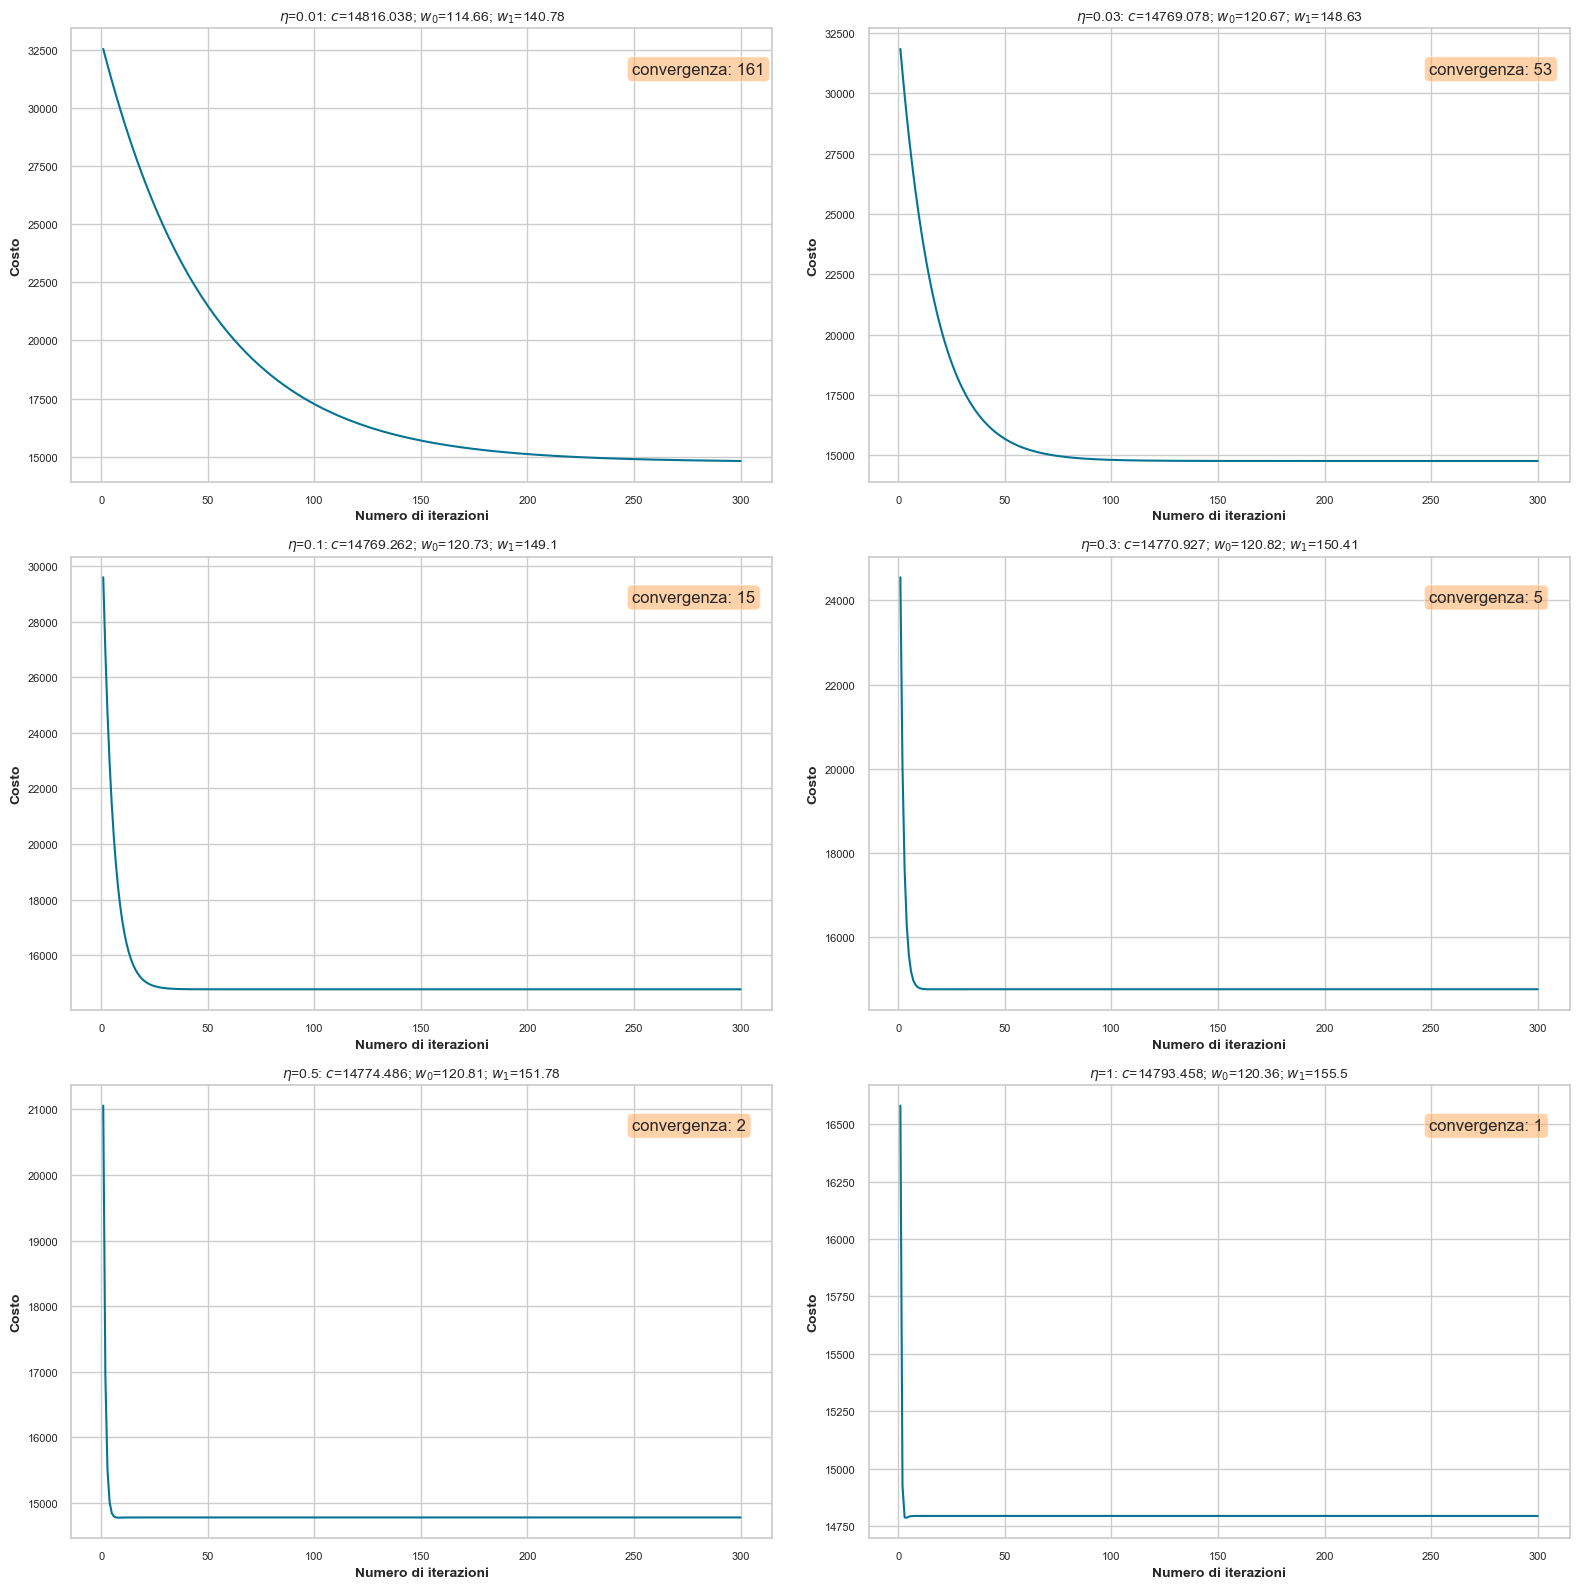

In [25]:
fig = plt.figure(figsize=(16,16))
for c,eta in enumerate(etas):
    costs, w = stochastic_gd(X, t, w_init, eta, epochs)
    max_index = np.max(np.where(costs > threshold)[0])+1
    ax = fig.add_subplot(3, 2, c+1)
    ax = fig.gca()
    sns.lineplot(x=np.ravel(number_of_iterations), y=np.ravel(costs), color=colors[1], alpha=1, linewidth=1.5, ax=ax)
    plt.xticks(fontsize=8)
    plt.yticks(fontsize=8)
    plt.xlabel(r'Numero di iterazioni', fontsize=10)
    plt.ylabel(r'Costo', fontsize=10)
    plt.text(0.8, 0.9, 'convergenza: {0:d}'.format(max_index), fontsize=12, 
         transform=ax.transAxes, bbox=bbox_props)
    plt.title(r'$\eta$='+str(eta)+r': $c$='+str(round(costs[-1].item(),3))+r'; $w_0$='
              +str(round(w[0][0],2))+'; $w_1$='+str(round(w[1][0],2))+'', fontsize=10)
plt.tight_layout()
plt.show()

Confronto in un unico grafico.

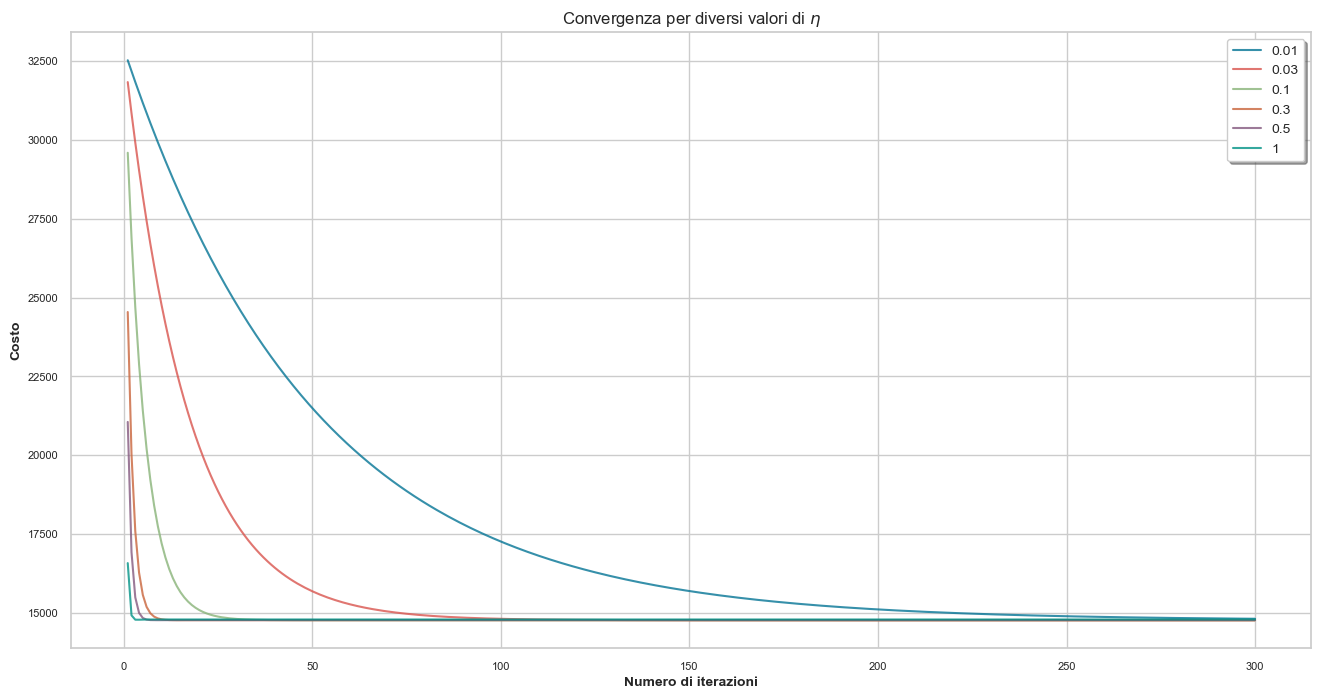

In [26]:
fig = plt.figure(figsize=(16,8))
ax = fig.gca()
for c,eta in enumerate(etas):
    costs, w = stochastic_gd(X, t, w_init, eta, epochs)
    sns.lineplot(x=np.ravel(number_of_iterations), y=np.ravel(costs), color=colors[c+1], alpha=.8, linewidth=1.5, label=eta, ax=ax)
plt.xticks(fontsize=8)
plt.yticks(fontsize=8)
plt.xlabel(r'Numero di iterazioni', fontsize=10)
plt.ylabel(r'Costo', fontsize=10)
legend = ax.legend(loc='upper right', shadow=True)
plt.title(r'Convergenza per diversi valori di $\eta$', fontsize=12)
plt.show()

## Discesa del gradiente con momento

La funzione `gradiente` è ridefinita identica a prima. Il metodo del **momento** mantiene una "velocità" $\mathbf{v}$, media esponenziale dei gradienti passati,
$$\mathbf{v}^{(k+1)}=\gamma\,\mathbf{v}^{(k)}-\eta\,\nabla E(\mathbf{w}^{(k)}),\qquad \mathbf{w}^{(k+1)}=\mathbf{w}^{(k)}+\mathbf{v}^{(k+1)},$$
con $\gamma\in[0,1)$. Lungo le direzioni in cui il gradiente mantiene lo stesso segno la velocità si accumula e il metodo accelera; lungo quelle in cui il gradiente cambia segno (le oscillazioni attraverso una valle stretta) i contributi si compensano e le oscillazioni si smorzano. Per $\gamma=0$ si ritrova la discesa del gradiente ordinaria.

In [27]:
def gradiente(X, t, w_init, eta, iterations, n):
    w = np.copy(w_init)
    costs = []
    for i in range(iterations):
        e=np.dot(X,w)-t
        c=np.dot(e.T,e)[0,0]/(2*n)
        dw=np.dot(X.T, e)/n
        w = w-eta*dw
        costs.append(c)
    return costs, w

In [28]:
def momentum_gd(X,t, theta_init, eta = 0.1, gamma = 0.97, epochs = 1000):
    theta = np.copy(theta_init)
    v = np.zeros(2).reshape(-1,1)
    cost_history = []
    for k in range(epochs):    
        e = np.dot(X,theta)-t
        v = gamma*v - eta * np.dot(X.T, e)/n
        theta = theta + v
        cost_history.append(np.dot(e.T,e)[0,0]/(2*n))
    cost_history = np.array(cost_history).reshape(-1,1)
    return cost_history, theta

In [29]:
w_init = np.array([0, 0]).reshape(-1,1)
    
iterations = 150
etas = [0.01, 0.03, 0.1, 0.3, 0.5, 1]

number_of_iterations = range(1, iterations + 1)

Usiamo $\gamma=0.7$.

In [30]:
gamma=.7

Con il momento la convergenza è più rapida, a parità di learning rate, rispetto alla discesa del gradiente semplice. Con learning rate grandi, però, la velocità accumulata può portare a superare il minimo, e il costo mostra oscillazioni prima di stabilizzarsi: il momento aggiunge "inerzia", utile nelle valli strette ma fonte di sovraelongazioni quando i passi sono già grandi.


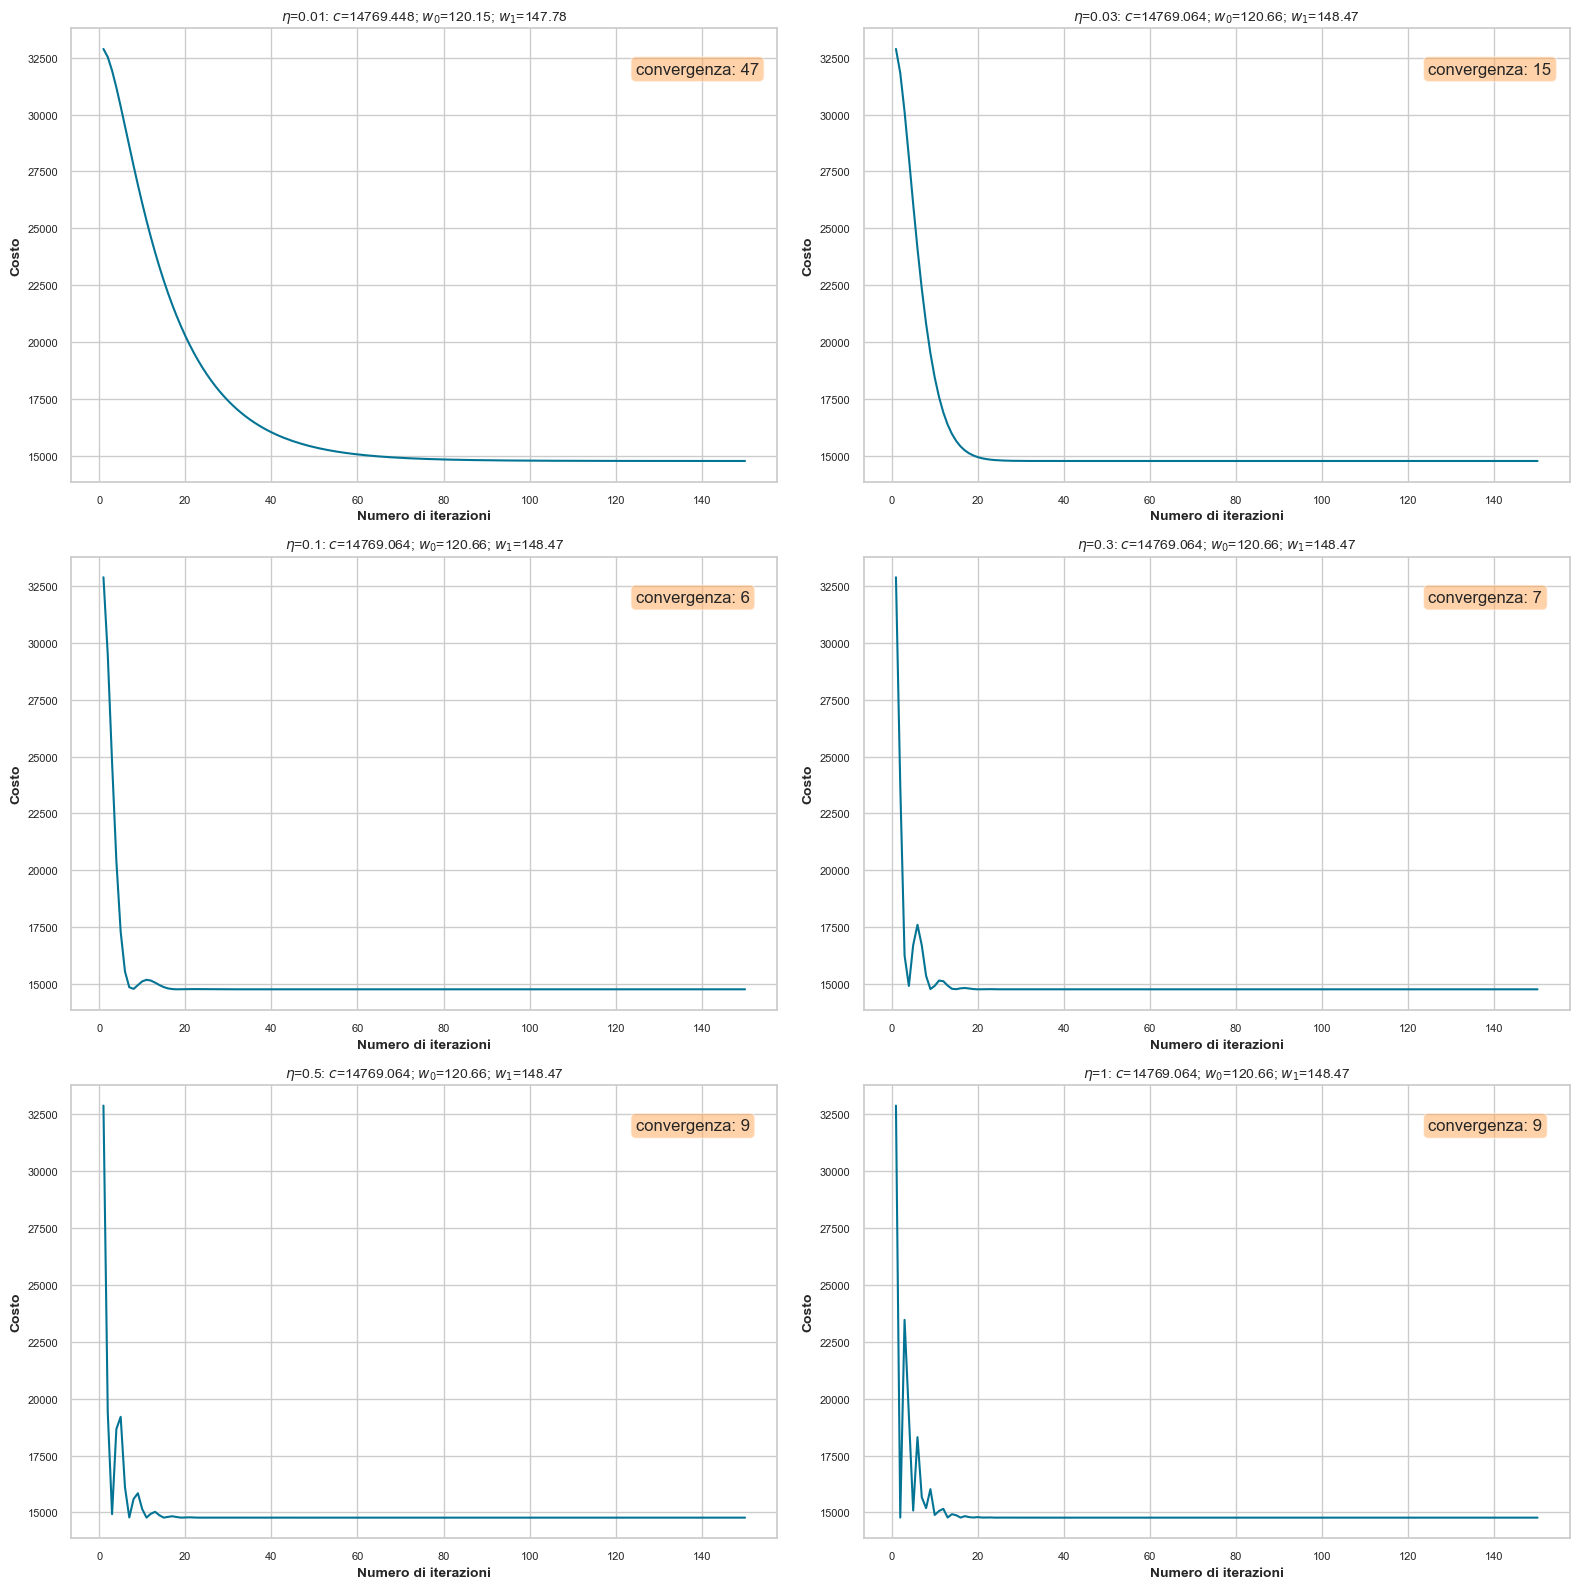

In [31]:
fig = plt.figure(figsize=(16,16))
for c,eta in enumerate(etas):
    costs, w = momentum_gd(X, t, w_init, eta, gamma, iterations)
    max_index = np.max(np.where(costs > threshold)[0])+1
    ax = fig.add_subplot(3, 2, c+1)
    ax = fig.gca()
    sns.lineplot(x=np.ravel(number_of_iterations), y=np.ravel(costs), color=colors[1], alpha=1, linewidth=1.5, ax=ax)
    plt.xticks(fontsize=8)
    plt.yticks(fontsize=8)
    plt.xlabel(r'Numero di iterazioni', fontsize=10)
    plt.ylabel(r'Costo', fontsize=10)
    plt.text(0.8, 0.9, 'convergenza: {0:d}'.format(max_index), fontsize=12, 
         transform=ax.transAxes, bbox=bbox_props)
    plt.title(r'$\eta$='+str(eta)+r': $c$='+str(round(costs[-1].item(),3))+r'; $w_0$='+str(round(w[0][0],2))+'; $w_1$='+str(round(w[1][0],2))+'', fontsize=10)
plt.tight_layout()
plt.show()

## Considerazioni finali

Per un modello lineare con loss quadratica e poche feature, come quello di questo notebook, la soluzione in forma chiusa è preferibile: è esatta, non richiede di scegliere un learning rate e costa la soluzione di un sistema lineare di dimensione pari al numero di parametri. I metodi iterativi diventano indispensabili quando il numero di parametri è molto grande, quando il dataset non entra in memoria (SGD e mini-batch elaborano pochi elementi alla volta), o quando la funzione da minimizzare non è quadratica, come per la regressione logistica o le reti neurali, in cui non esiste una soluzione in forma chiusa. In tutti questi casi valgono le stesse considerazioni viste qui: l'importanza della normalizzazione delle feature, la scelta del learning rate, il compromesso tra costo per iterazione e rumore della stima del gradiente.